# QUBO Benchmark Ladder: Validation to Hardware-Scale Stress

This notebook is the showcase view of the QUBO research programme. It does not replace the detailed construction in notebook 13, the Seren energy analysis in notebook 19, or the hard-target protocol in notebook 21. It connects them through one comparable ladder.

The ladder answers four separate questions:

1. Does the QUBO encode the intended constraints on hand-checkable cases?
2. At what size can local annealing still return feasible schedules?
3. Where does Gurobi remain fast, and where does proving optimality become expensive?
4. When does the logical QUBO graph become unsuitable for direct near-term hardware?

## Levels and interpretation

| Level | Instance | Primary purpose |
|---|---|---|
| L0 | 3 jobs, 3 hourly slots | Term-by-term Hamiltonian validation |
| L1 | Seren tiny, 6 jobs, hourly | First decoded-schedule feasibility check |
| L2 | Seren small, 12 jobs, hourly | Penalty calibration and energy-quality comparison |
| L3 | Seren medium, 24 jobs, hourly | Observe feasibility and graph growth under a larger trace-derived workload |
| L4 | Existing synthetic A100 classical bridge, 45 jobs, 15-minute slots | Gurobi proves the requested gap, but certification takes materially longer; it is not yet the reduced quantum bridge |
| L5 | Synthetic A100 hard target, 42 jobs, 15-minute slots | Gurobi has an incumbent but reaches the time limit with a nonzero gap; direct QUBO hardware scale is characterized |

L4 and L5 use a single 256-node A100 partition. Their jobs are multi-node, multi-slot, price-sensitive, and planted feasible. The hidden placement is used only to certify that a feasible schedule exists; neither Gurobi nor QUBO receives it.

## Fair-comparison rule

The full MILP optimizes physical renewable/grid dispatch and grid-import peak billing. The reduced QUBO uses effective time prices and a squared-load peak proxy. Therefore this notebook records:

- QUBO energy: the reduced Hamiltonian value;
- decoded feasibility: assignment, start-window, and GPU-capacity checks;
- physical post-evaluation: renewable use, grid import, PUE, and grid-import peak;
- Gurobi status, runtime, and MIP gap.

Only valid decoded schedules are allowed into physical cost comparisons.



In [1]:
from __future__ import annotations

from pathlib import Path
from time import perf_counter

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dwave.samplers import SimulatedAnnealingSampler

from src.config import ModelConfig
from src.quantum.benchmarking import (
    add_effective_price_for_qubo,
    evaluate_physical_schedule,
    make_effective_price_qubo_inputs,
)
from src.quantum.qubo_builder import (
    QuboPenaltyWeights,
    build_scheduling_qubo,
    decode_qubo_sample,
    summarize_qubo_graph,
    to_dimod_bqm,
    validate_decoded_schedule,
)



In [2]:
REPOSITORY_ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
SEREN_ROOT = REPOSITORY_ROOT / 'data/instances/seren_pretrain'
STRESS_ROOT = REPOSITORY_ROOT / 'data/instances/single_cluster_15m/long_duration_focused'

# L4 is an existing classical-runtime bridge. Its logical QUBO is larger
# than L5, so a short-horizon quantum bridge remains a separate task.
# L5 has a feasible Gurobi incumbent but a nonzero final MIP gap.
L4_DIRECTORY = STRESS_ROOT / 'long_high_util_wide_seed_7601'
L5_DIRECTORY = STRESS_ROOT / 'long_wide_window_seed_7602'

RUN_LOCAL_ANNEALING = False
ANNEALING_LEVELS = ('L0', 'L1', 'L2', 'L3')
NUM_READS = 100
RANDOM_SEED = 41

# These are an initial screening configuration, not calibrated final weights.
# Calibrate on development instances before running L4 or L5.
SCREENING_WEIGHTS = QuboPenaltyWeights(
    assignment=1_000.0,
    gpu_capacity=0.01,
    peak_smoothing=0.01,
)



In [3]:
def proxy_config(clusters: pd.DataFrame, energy: pd.DataFrame, delta_t: float) -> ModelConfig:
    """Build the scalar configuration required by the reduced QUBO builder."""

    return ModelConfig(
        contracted_power=float(clusters['capacity'].sum()) * 10.0,
        renewable_price=1_000_000.0,
        peak_price=0.0,
        delta_t=delta_t,
        pue=float(energy['pue'].iloc[0]),
    )


def build_l0_instance() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, float, str]:
    """Create the hand-checkable three-job QUBO instance used in notebook 13."""

    jobs = pd.DataFrame([
        {'job_id': 'l0_j1', 'category': 'gpu', 'duration': 1, 'power': 0.010, 'earliest_start': 0, 'latest_start': 1, 'gpu_count_required': 1, 'compatible_clusters': 'l0_cluster'},
        {'job_id': 'l0_j2', 'category': 'gpu', 'duration': 1, 'power': 0.010, 'earliest_start': 0, 'latest_start': 2, 'gpu_count_required': 1, 'compatible_clusters': 'l0_cluster'},
        {'job_id': 'l0_j3', 'category': 'gpu', 'duration': 1, 'power': 0.010, 'earliest_start': 1, 'latest_start': 2, 'gpu_count_required': 1, 'compatible_clusters': 'l0_cluster'},
    ])
    clusters = pd.DataFrame([{'cluster_id': 'l0_cluster', 'capacity': 0.020, 'gpu_count': 2, 'gpu_capacity': 2}])
    energy = pd.DataFrame({
        'hour': [0, 1, 2],
        'grid_price': [100.0, 40.0, 80.0],
        'renewable_available': [0.0, 0.020, 0.0],
        'renewable_price': [30.0, 30.0, 30.0],
        'pue': [1.25, 1.25, 1.25],
        'baseline_load': [0.0, 0.0, 0.0],
    })
    return jobs, clusters, energy, 1.0, 'hand-checkable QUBO term validation'


def load_seren_level(name: str) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, float, str]:
    """Load a one-hour Seren level and derive its instance-specific QUBO price."""

    directory = SEREN_ROOT / name
    jobs = pd.read_csv(directory / 'jobs.csv')
    clusters = pd.read_csv(directory / 'clusters.csv')
    energy = pd.read_csv(directory / 'hourly_inputs.csv')
    energy['pue'] = energy.get('pue', pd.Series(1.25, index=energy.index))
    energy['baseline_load'] = energy.get('baseline_load', pd.Series(0.0, index=energy.index))
    return jobs, clusters, add_effective_price_for_qubo(energy, jobs, clusters), 1.0, 'trace-derived hourly instance'


def load_stress_level(directory: Path, role: str) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, float, str]:
    """Load a persisted one-cluster 15-minute stress instance and Gurobi summary."""

    jobs = pd.read_csv(directory / 'jobs.csv')
    clusters = pd.read_csv(directory / 'clusters.csv')
    energy = pd.read_csv(directory / 'energy_inputs_15m.csv')
    metadata = pd.read_json(directory / 'generation_metadata.json', typ='series')
    gurobi = pd.read_csv(directory / 'gurobi_summary.csv').iloc[0].to_dict()
    return jobs, clusters, energy, 0.25, role, metadata, gurobi



In [4]:
l0_jobs, l0_clusters, l0_energy, l0_delta_t, l0_role = build_l0_instance()
l1_jobs, l1_clusters, l1_energy, l1_delta_t, l1_role = load_seren_level('tiny_6_jobs')
l2_jobs, l2_clusters, l2_energy, l2_delta_t, l2_role = load_seren_level('small_12_jobs')
l3_jobs, l3_clusters, l3_energy, l3_delta_t, l3_role = load_seren_level('medium_24_jobs')
l4_jobs, l4_clusters, l4_energy, l4_delta_t, l4_role, l4_metadata, l4_gurobi = load_stress_level(L4_DIRECTORY, 'existing 15-minute classical bridge: slower optimality certification')
l5_jobs, l5_clusters, l5_energy, l5_delta_t, l5_role, l5_metadata, l5_gurobi = load_stress_level(L5_DIRECTORY, '15-minute hard target: time-limited Gurobi proof')

LEVELS = {
    'L0': {'jobs': l0_jobs, 'clusters': l0_clusters, 'energy': l0_energy, 'delta_t': l0_delta_t, 'role': l0_role, 'gurobi': None},
    'L1': {'jobs': l1_jobs, 'clusters': l1_clusters, 'energy': l1_energy, 'delta_t': l1_delta_t, 'role': l1_role, 'gurobi': None},
    'L2': {'jobs': l2_jobs, 'clusters': l2_clusters, 'energy': l2_energy, 'delta_t': l2_delta_t, 'role': l2_role, 'gurobi': None},
    'L3': {'jobs': l3_jobs, 'clusters': l3_clusters, 'energy': l3_energy, 'delta_t': l3_delta_t, 'role': l3_role, 'gurobi': None},
    'L4': {'jobs': l4_jobs, 'clusters': l4_clusters, 'energy': l4_energy, 'delta_t': l4_delta_t, 'role': l4_role, 'gurobi': l4_gurobi},
    'L5': {'jobs': l5_jobs, 'clusters': l5_clusters, 'energy': l5_energy, 'delta_t': l5_delta_t, 'role': l5_role, 'gurobi': l5_gurobi},
}



## Structural QUBO profile

The next cell builds every QUBO without sampling it. This is cheap enough to run routinely and shows why logical variables alone are not a sufficient hardware-scale measure.


In [5]:
def profile_level(level: str, payload: dict) -> tuple[dict, object]:
    """Build one reduced QUBO and return solver-independent structural metrics."""

    jobs = payload['jobs']
    clusters = payload['clusters']
    energy = payload['energy']
    if 'effective_price' not in energy.columns:
        energy = add_effective_price_for_qubo(energy, jobs, clusters)
    qubo_energy = make_effective_price_qubo_inputs(energy)
    qubo = build_scheduling_qubo(
        jobs,
        qubo_energy,
        clusters,
        proxy_config(clusters, energy, payload['delta_t']),
        SCREENING_WEIGHTS,
    )
    graph = summarize_qubo_graph(qubo)
    starts = jobs['latest_start'] - jobs['earliest_start'] + 1
    row = {
        'level': level,
        'role': payload['role'],
        'jobs': len(jobs),
        'slots': len(energy),
        'delta_t_h': payload['delta_t'],
        'mean_duration_slots': float(jobs['duration'].mean()),
        'mean_start_options': float(starts.mean()),
        **graph,
        'gurobi_runtime_s': None,
        'gurobi_status': None,
        'gurobi_mip_gap': None,
    }
    if payload['gurobi'] is not None:
        row['gurobi_runtime_s'] = float(payload['gurobi']['runtime_s'])
        row['gurobi_status'] = int(payload['gurobi']['status'])
        row['gurobi_mip_gap'] = float(payload['gurobi']['mip_gap'])
    return row, qubo


profiles = {}
qubos = {}
for level, payload in LEVELS.items():
    profiles[level], qubos[level] = profile_level(level, payload)

ladder_summary = pd.DataFrame(profiles.values())
display(ladder_summary[
    ['level', 'jobs', 'slots', 'mean_duration_slots', 'mean_start_options',
     'assignment_variables', 'slack_variables', 'logical_variables',
     'quadratic_couplers', 'coupling_density', 'gurobi_runtime_s', 'gurobi_mip_gap']
])



,level,jobs,slots,mean_duration_slots,mean_start_options,assignment_variables,slack_variables,logical_variables,quadratic_couplers,coupling_density,gurobi_runtime_s,gurobi_mip_gap
0,L0,3,3,1.000000,2.333333,7,6,13,27,0.346154,NaN,NaN
1,L1,6,24,1.000000,4.166667,25,40,65,287,0.137981,NaN,NaN
2,L2,12,24,1.000000,3.500000,42,110,152,513,0.044702,NaN,NaN
3,L3,24,24,1.000000,4.083333,98,105,203,1093,0.053309,NaN,NaN
4,L4,45,96,9.688889,17.022222,766,864,1630,135097,0.101758,26.371395,0.000985
5,L5,42,96,9.142857,16.738095,703,864,1567,113091,0.092172,60.007171,0.010206


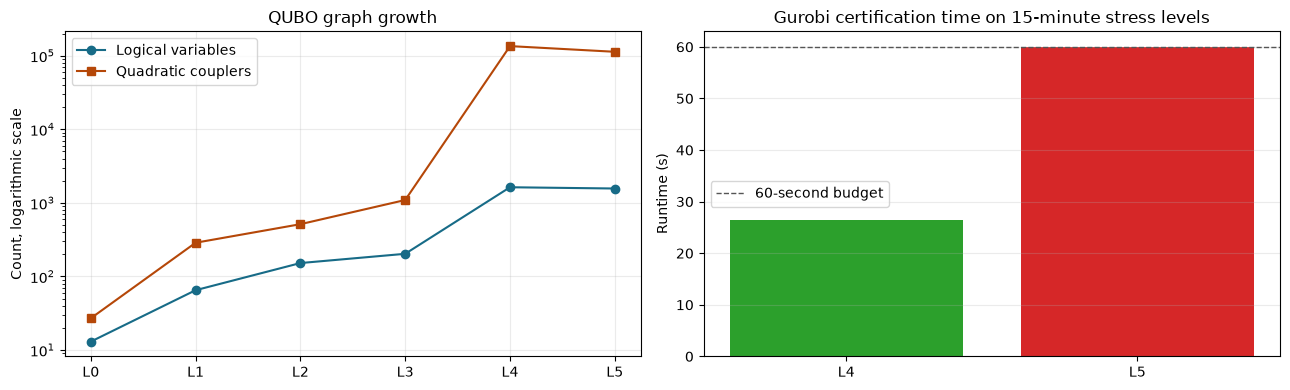

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(ladder_summary['level'], ladder_summary['logical_variables'], marker='o', color='#176b87', label='Logical variables')
axes[0].plot(ladder_summary['level'], ladder_summary['quadratic_couplers'], marker='s', color='#b54708', label='Quadratic couplers')
axes[0].set_yscale('log')
axes[0].set_title('QUBO graph growth')
axes[0].set_ylabel('Count, logarithmic scale')
axes[0].grid(alpha=0.25)
axes[0].legend()

classical = ladder_summary.dropna(subset=['gurobi_runtime_s'])
axes[1].bar(classical['level'], classical['gurobi_runtime_s'], color=['#2ca02c', '#d62728'])
axes[1].axhline(60, linestyle='--', color='#555555', linewidth=1, label='60-second budget')
axes[1].set_title('Gurobi certification time on 15-minute stress levels')
axes[1].set_ylabel('Runtime (s)')
axes[1].grid(axis='y', alpha=0.25)
axes[1].legend()

plt.tight_layout()
plt.show()



## Optional local annealing

Set RUN_LOCAL_ANNEALING to True after selecting calibrated weights. The default excludes L4 and L5 because their penalty calibration must not reuse the held-out hard target.


In [7]:
def assignment_error_count(schedule: pd.DataFrame, jobs: pd.DataFrame) -> int:
    """Count missing jobs plus extra assignments in a decoded schedule."""

    counts = schedule['job_id'].value_counts() if not schedule.empty else pd.Series(dtype=int)
    return sum(abs(int(counts.get(job_id, 0)) - 1) for job_id in jobs['job_id'])


def sample_level(level: str, payload: dict, qubo) -> dict:
    """Sample a QUBO locally and retain the best physically feasible sample."""

    started = perf_counter()
    sampleset = SimulatedAnnealingSampler().sample(
        to_dimod_bqm(qubo), num_reads=NUM_READS, seed=RANDOM_SEED
    )
    runtime_s = perf_counter() - started
    candidates = []
    hours = payload['energy']['hour'].astype(int).tolist()
    for record in sampleset.data(fields=['sample', 'energy']):
        schedule = decode_qubo_sample(qubo, dict(record.sample))
        validation = validate_decoded_schedule(schedule, payload['jobs'], payload['clusters'], hours)
        candidates.append({
            'qubo_energy': float(record.energy),
            'schedule': schedule,
            'validation': validation,
            'assignment_errors': assignment_error_count(schedule, payload['jobs']),
        })

    feasible = [item for item in candidates if item['validation']['feasible']]
    selected = min(
        feasible or candidates,
        key=lambda item: (not item['validation']['feasible'], item['assignment_errors'], item['qubo_energy']),
    )
    profile, physical = evaluate_physical_schedule(
        selected['schedule'],
        payload['energy'],
        delta_t=payload['delta_t'],
        contracted_power_mw=None,
        peak_price=0.0,
    )
    return {
        'level': level,
        'reads': NUM_READS,
        'runtime_s': runtime_s,
        'feasible_samples': len(feasible),
        'selected_feasible': selected['validation']['feasible'],
        'assignment_errors': selected['assignment_errors'],
        'qubo_energy': selected['qubo_energy'],
        **physical,
        'schedule': selected['schedule'],
        'physical_profile': profile,
    }


if RUN_LOCAL_ANNEALING:
    annealing_results = pd.DataFrame([
        {key: value for key, value in sample_level(level, LEVELS[level], qubos[level]).items() if key not in {'schedule', 'physical_profile'}}
        for level in ANNEALING_LEVELS
    ])
    display(annealing_results)



## How to read the ladder

- L0 is a correctness gate. Its expected solution can be reasoned about by inspection.
- L1-L3 measure whether a reduced QUBO remains usable as trace-derived job count grows.
- L4 is an existing classical bridge: its Gurobi run reaches the requested 0.1% gap, but it requires about 26 seconds. It is useful for showing a gradual classical-runtime transition. Its 1,630 logical variables are, however, slightly above L5, so it is not yet the intended reduced quantum bridge.
- L5 is the scale boundary: Gurobi has a feasible incumbent after its 60-second limit but retains a 1.02% gap. Its QUBO has more than 1,500 logical variables and more than 100,000 couplers.

The next benchmark-construction task is a 20-30 job, 6-12 hour, 15-minute instance with multi-node, multi-slot jobs and broad price-sensitive windows. It must retain a QUBO below L5 while making Gurobi certification slower than L3.

The thesis claim supported by this ladder is not that quantum hardware currently outperforms Gurobi. It is that the project has an auditable path from exact formulation validation to increasingly difficult combinatorial schedules, together with explicit evidence of where full QUBO size becomes a hardware constraint.

